[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phildani7/why-book-of-deep-learning-part-2/blob/main/notebooks/ch34_LabCh34_Position_Encodings.ipynb)

**The Why Book of Deep Learning, Part 2** by Dr. Philemon Paul Daniel

**Chapter 34: Position: Telling a Transformer Where Things Are** (Part VIII: Language Models).

* Read this chapter free online: [www.micyaai.com/books/why-deep-learning-2/read.html?ch=34](https://www.micyaai.com/books/why-deep-learning-2/read.html?ch=34)
* Part 1 of the book and its notebooks: [github.com/phildani7/why-book-of-deep-learning-part-1](https://github.com/phildani7/why-book-of-deep-learning-part-1)
* The simplified video course for kids: [aikids.guru](https://www.aikids.guru)
* All the notebooks for the book: [github.com/phildani7/why-book-of-deep-learning-part-2](https://github.com/phildani7/why-book-of-deep-learning-part-2)

Tested with TensorFlow 2.21 and Keras 3.14 on a laptop CPU (about five minutes or less). In Colab:
*Runtime > Run all*. It runs on the free CPU runtime; a GPU runtime works too and is usually faster, but the
printed timings and some last digits will differ from the saved outputs.

---


# Lab Ch34 - Position encodings
## Show that attention is blind to order, then give it positions five different ways

This lab goes with **Chapter 34** of *The Why Book of Deep Learning, Part 2*.

Self-attention treats its input as a bag. Shuffle the tokens and the outputs are shuffled the same way, and
nothing else changes. So order has to be put in by hand, and there are three places to put it: in the input
vector, in the queries and keys, or in the attention scores. In this lab you prove the bag property in NumPy,
build the classic sinusoidal table and look at it, and then train one small transformer six times on a task
where order is the whole question. The six runs differ in one argument.

| Run | Where position enters | Extra parameters |
|---|---|---|
| `none` | nowhere | 0 |
| `learnt` | a trainable table added to the input (BERT, GPT-2) | 128 × 32 |
| `sinusoid` | a fixed table of sines and cosines added to the input (2017) | 0 |
| `rope` | queries and keys are rotated by their position (2021) | 0 |
| `relbias` | a learnt number per offset is added to the attention scores (the T5 idea) | 2 × 2 × 17 |
| `none` + causal mask | nowhere, but each token sees only the tokens before it | 0 |

### What you will be able to do afterwards

| Skill | Where |
|---|---|
| State and check the permutation fact for self-attention | Steps 2 and 3 |
| Build the sinusoidal table and read its stripes as clock hands | Steps 4 and 5 |
| Say why adding a position to a token does not destroy the token | Step 6 |
| Rotate a query and a key (RoPE) and check that only the offset matters | Step 7 |
| Put position into a model in three different places, and count what each costs | Steps 9 and 10 |
| Recognise the plateau of a model that was given no positions | Steps 11 and 12 |
| Test a model on sequences longer than it trained on, and explain what you see | Steps 13 to 15 |
| Explain why a causal mask is itself a position signal | Step 16 |

### The rule of this lab: predict, then run

Every step asks you to **write down a prediction before you run the cell**. A wrong prediction that you
understand afterwards is worth more than a right one you guessed.

> **Runtime:** two to three minutes on a laptop CPU, nearly all of it in Steps 12 and 16. No GPU, no downloads.

> **Honest scale:** the models here have about 17,500 parameters and solve a toy task on sequences of 8 to 128
> tokens. The lab shows *mechanisms*: what a model without positions cannot do, and which way of adding
> positions survives a longer input. It does not tell you what accuracy any scheme reaches in a full-size
> language model, and the exact numbers move a little with the seed.

---
## Step 1 - Imports and one seed

In [1]:
import os, time
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, ops

SEED = 34
keras.utils.set_random_seed(SEED)
rng = np.random.default_rng(SEED)
np.set_printoptions(precision=3, suppress=True, linewidth=120)
t_start = time.time()
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

TensorFlow 2.21.0 | Keras 3.14.1


---
## Step 2 - Self-attention in NumPy, and a shuffle

Chapter 22 built self-attention by hand: every token makes a query, a key and a value; the scores are the dot
products of queries with keys; a softmax turns each row of scores into weights; the output is the weighted
mix of the values. Here it is again in eight lines, with random weights, for 6 tokens of width 8.

We run it twice: on the tokens in order, and on the same tokens shuffled.

> **Predict:** the second output has the same 6 rows as the first. In what order? And will the *numbers* in
> a row change because its neighbours changed?

In [2]:
def softmax(z):
    z = z - z.max(axis=-1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=-1, keepdims=True)


def self_attention(X, Wq, Wk, Wv, causal=False):
    """One attention head, no positions. X has shape (T, d)."""
    Q, K, Vv = X @ Wq, X @ Wk, X @ Wv
    scores = Q @ K.T / np.sqrt(K.shape[1])
    if causal:
        scores = np.where(np.triu(np.ones_like(scores), k=1) == 1, -1e9, scores)
    return softmax(scores) @ Vv


T_demo, d_demo = 6, 8
X = rng.normal(size=(T_demo, d_demo))
Wq, Wk, Wv = (rng.normal(size=(d_demo, d_demo)) for _ in range(3))

perm = rng.permutation(T_demo)
out_in_order = self_attention(X, Wq, Wk, Wv)
out_shuffled = self_attention(X[perm], Wq, Wk, Wv)

print("the shuffle:", perm)
print("largest difference between out_shuffled and out_in_order[perm]:",
      f"{np.abs(out_shuffled - out_in_order[perm]).max():.1e}")
print("largest difference between the two pooled (mean) outputs:      ",
      f"{np.abs(out_shuffled.mean(axis=0) - out_in_order.mean(axis=0)).max():.1e}")
assert np.allclose(out_shuffled, out_in_order[perm])

the shuffle: [0 5 2 1 4 3]
largest difference between out_shuffled and out_in_order[perm]: 8.9e-16
largest difference between the two pooled (mean) outputs:       2.2e-16


### Why we see this

The two differences are zero up to rounding. Every row of the output is "this token's query against *all*
keys", and a sum over all keys does not care what order the keys stand in. So each token gets exactly the
vector it got before, and the rows come out in the shuffled order. That property has a name:
self-attention is **permutation-equivariant** (shuffle the input, and the output is shuffled the same way).

Pool the rows into one vector (a mean, a max) and even the shuffle disappears: the pooled result is
**permutation-invariant**. A classifier built this way gives *the same answer for every ordering of its
input*. The feed-forward layer, the residual additions and LayerNorm do not help, because each of them works
on one position at a time.

---
## Step 3 - The same shuffle on a recurrent network, and under a causal mask

Two comparisons. A recurrent layer (Chapter 19) reads the tokens one after another, so order is built into
the computation. And attention under a **causal mask** (Chapter 22: each token may look only at itself and
earlier tokens) is no longer the same function for every position.

> **Predict:** for each of the two, will the shuffled output equal the shuffled original? Yes or no.

In [3]:
def rnn_states(X, Wx, Wh):
    h, out = np.zeros(Wh.shape[0]), []
    for x in X:                               # one token after another: order is in the loop
        h = np.tanh(x @ Wx + h @ Wh)
        out.append(h)
    return np.array(out)


Wx, Wh = rng.normal(size=(d_demo, d_demo)) * 0.5, rng.normal(size=(d_demo, d_demo)) * 0.5
rnn_diff = np.abs(rnn_states(X[perm], Wx, Wh) - rnn_states(X, Wx, Wh)[perm]).max()

causal_in_order = self_attention(X, Wq, Wk, Wv, causal=True)
causal_shuffled = self_attention(X[perm], Wq, Wk, Wv, causal=True)
causal_diff = np.abs(causal_shuffled - causal_in_order[perm]).max()

print(f"recurrent network:        largest difference {rnn_diff:.3f}   (not equivariant)")
print(f"attention + causal mask:  largest difference {causal_diff:.3f}   (not equivariant)")
assert rnn_diff > 1e-3 and causal_diff > 1e-3

recurrent network:        largest difference 1.854   (not equivariant)
attention + causal mask:  largest difference 8.782   (not equivariant)


### Why we see this

The recurrent network's state at step t depends on everything before step t *in that order*. A convolution
has the same kind of built-in order: its kernel has a left end and a right end. Neither ever needed a
position signal. Attention gave up the built-in order to gain parallelism and long reach (Chapters 21, 22),
and this chapter is the bill.

The causal mask is the interesting one. With the mask, the first token attends to one token, the second to
two, the tenth to ten: each position sees a different *amount* of input, and which tokens it sees depends on
where it stands. So a decoder with no position encoding at all can still work out some order information.
We come back to this in Step 16 and measure it.

---
## Step 4 - The sinusoidal table (2017)

The original transformer gave each position a fixed fingerprint. Take the width d in pairs. Pair number i
is a clock hand: it turns by `1 / 10000^(2i/d)` radians per position, and the pair stores the sine and the
cosine of the hand's angle. The first pair turns fast (one radian per position, a full turn every 6.28
positions); each later pair turns more slowly, the speeds falling in equal ratios.

We build the table for 128 positions and width 32: the width our models will use.

> **Predict:** the fastest hand needs 6.28 positions for a full turn. Roughly how many positions does the
> *slowest* of the 16 hands need: about 100, about 1,000, or tens of thousands?

table shape: (128, 32) | trainable parameters: 0
positions per full turn, hand 0 (fastest): 6.28
positions per full turn, hand 8          : 628.3
positions per full turn, hand 15 (slowest): 35,333

first 4 positions, first 6 of the 32 numbers:
[[ 0.     1.     0.     1.     0.     1.   ]
 [ 0.841  0.54   0.533  0.846  0.311  0.95 ]
 [ 0.909 -0.416  0.902  0.431  0.591  0.807]
 [ 0.141 -0.99   0.993 -0.116  0.813  0.583]]


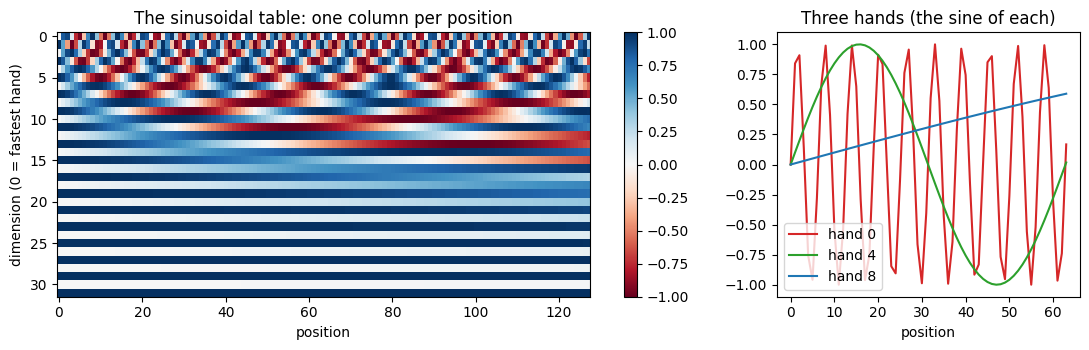

In [4]:
D = 32            # model width
T_MAX = 128       # the longest sequence we will ever feed in


def sinusoid_table(n_pos, d, base=10000.0):
    """Row p is the fingerprint of position p. Shape (n_pos, d)."""
    pos = np.arange(n_pos)[:, None]                 # (n_pos, 1)
    i = np.arange(d // 2)[None, :]                  # (1, d/2)   one column per clock hand
    angle = pos / base ** (2 * i / d)               # radians turned by hand i at position pos
    table = np.zeros((n_pos, d), dtype="float32")
    table[:, 0::2] = np.sin(angle)
    table[:, 1::2] = np.cos(angle)
    return table


P = sinusoid_table(T_MAX, D)
wavelength = 2 * np.pi * 10000.0 ** (2 * np.arange(D // 2) / D)
print("table shape:", P.shape, "| trainable parameters: 0")
print("positions per full turn, hand 0 (fastest):", f"{wavelength[0]:.2f}")
print("positions per full turn, hand 8          :", f"{wavelength[8]:.1f}")
print("positions per full turn, hand 15 (slowest):", f"{wavelength[15]:,.0f}")
print("\nfirst 4 positions, first 6 of the 32 numbers:")
print(P[:4, :6])

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [2.2, 1]})
im = ax[0].imshow(P.T, aspect="auto", cmap="RdBu", vmin=-1, vmax=1)
ax[0].set_xlabel("position"); ax[0].set_ylabel("dimension (0 = fastest hand)")
ax[0].set_title("The sinusoidal table: one column per position")
plt.colorbar(im, ax=ax[0])
for hand, colour in [(0, "tab:red"), (4, "tab:green"), (8, "tab:blue")]:
    ax[1].plot(P[:64, 2 * hand], color=colour, label=f"hand {hand}")
ax[1].set_xlabel("position"); ax[1].set_title("Three hands (the sine of each)"); ax[1].legend()
plt.tight_layout(); plt.show()

### Why we see this

The picture is striped: fine stripes at the top (fast hands), broad bands lower down (slow hands), and the
slowest rows hardly change across 128 positions. Read one column from top to bottom and you are reading a
clock with sixteen hands. The fast hands tell neighbours apart; the slow hands tell the beginning of a long
text from the end. No single hand could do both jobs, which is why the speeds are spread out in equal
ratios, like seconds, minutes and hours.

The slowest hand in a width-32 table needs about 35,000 positions for one turn. In the original paper's
width of 512 it is about 60,600. The table is a pure function of the position: nothing to train, nothing to
store, and it can be computed for position 5,000 as easily as for position 5.

---
## Step 5 - How similar are two positions?

A model compares vectors with dot products. So take the dot product of every position's fingerprint with
every other's.

> **Predict:** the dot product of a fingerprint with itself is the same for every position. What is it?
> (Each of the 16 hands contributes sin² + cos².) And will the similarity of positions 10 and 13 equal that
> of positions 100 and 103?

position with itself: [16. 16. 16. 16.] ...

offset k   similarity of p and p + k   (same for every p?)
      1     15.314                 spread across p: 5.7e-06
      2     13.730                 spread across p: 5.7e-06
      4     11.662                 spread across p: 3.8e-06
      8     10.522                 spread across p: 2.9e-06
     16      7.925                 spread across p: 2.4e-06
     32      9.625                 spread across p: 2.9e-06
     64      8.596                 spread across p: 9.5e-07


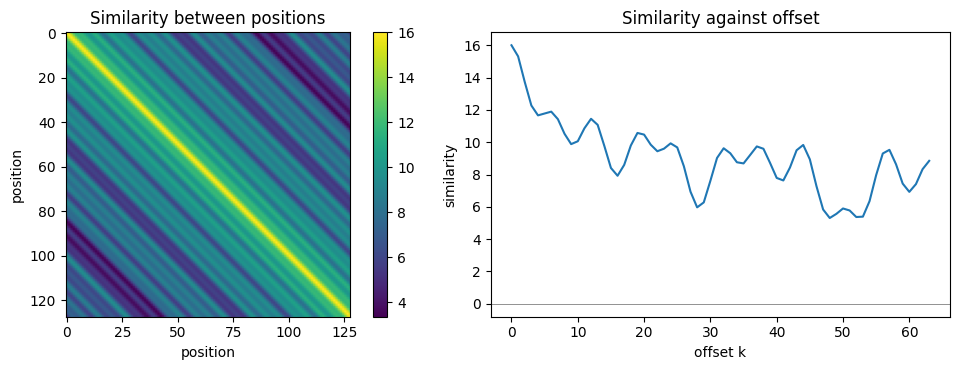

In [5]:
S = P @ P.T                                   # (128, 128): similarity of every pair of positions
print("position with itself:", np.round(np.diag(S)[:4], 3), "...")
print("\noffset k   similarity of p and p + k   (same for every p?)")
for k in (1, 2, 4, 8, 16, 32, 64):
    line = np.array([S[p, p + k] for p in range(T_MAX - k)])
    print(f"{k:7d}   {line[0]:8.3f}                 spread across p: {line.max() - line.min():.1e}")
    assert line.max() - line.min() < 1e-3

fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.8))
im = ax[0].imshow(S, cmap="viridis"); plt.colorbar(im, ax=ax[0])
ax[0].set_title("Similarity between positions"); ax[0].set_xlabel("position"); ax[0].set_ylabel("position")
ax[1].plot(np.arange(64), S[0, :64]); ax[1].axhline(0, color="grey", lw=0.6)
ax[1].set_xlabel("offset k"); ax[1].set_ylabel("similarity"); ax[1].set_title("Similarity against offset")
plt.tight_layout(); plt.show()

### Why we see this

The heat map is a bright diagonal band that looks the same all the way down: the similarity of two
fingerprints depends **only on how far apart they are**, never on where they are. (For each hand,
sin a · sin b + cos a · cos b = cos(a − b), and a − b is the offset times the hand's speed.) Nearby positions
are similar, distant ones less so, and the fall is smooth for the first few steps.

This is the property that made the designers hopeful: the table writes absolute positions, but relative
offsets are sitting in it, readable with a dot product. Whether a trained model *uses* them that way, and
keeps doing so beyond the lengths it trained on, is a separate question. Step 13 asks it.

---
## Step 6 - Does adding a position destroy the token?

The table is **added** to the token vectors: same shape in, same shape out, `(batch, T, d)`. It looks like
vandalism: two different things summed into one vector. The test: make 1,000 random token vectors, add a
position to each, then try to read back *which token* and *which position* went in, using nothing cleverer
than "nearest row of the table".

> **Predict:** at width 64, what fraction of the tokens can be read back: about half, about 90%, or nearly
> all? And at width 4?

In [6]:
def read_back(d, n_tokens=1000, n_pos=128, n_trials=20000, seed=0):
    """Add a random token row to a position row; find the nearest token row and nearest position row."""
    r = np.random.default_rng(seed)
    E = r.normal(size=(n_tokens, d)) / np.sqrt(2)          # token table, about the same length as a position row
    Pd = sinusoid_table(n_pos, d)
    tok, pos = r.integers(0, n_tokens, n_trials), r.integers(0, n_pos, n_trials)
    summed = E[tok] + Pd[pos]

    def nearest(table):                                    # index of the closest row, for every summed vector
        d2 = (summed ** 2).sum(1)[:, None] - 2 * summed @ table.T + (table ** 2).sum(1)[None, :]
        return d2.argmin(axis=1)

    cos = (E @ Pd.T) / (np.linalg.norm(E, axis=1)[:, None] * np.linalg.norm(Pd, axis=1)[None, :])
    near = np.abs(nearest(Pd) - pos) <= 2                  # neighbouring fingerprints are alike by design
    return (nearest(E) == tok).mean(), (nearest(Pd) == pos).mean(), near.mean(), np.abs(cos).mean()


print("width d   token read back   position exact   position within 2   mean |cosine| token vs position")
for d in (4, 16, 64, 256):
    tok_ok, pos_ok, pos_near, cos = read_back(d)
    print(f"{d:7d}   {tok_ok:14.1%}   {pos_ok:13.1%}   {pos_near:16.1%}   {cos:14.3f}")

width d   token read back   position exact   position within 2   mean |cosine| token vs position


      4             1.5%            4.4%               7.3%            0.423


     16            49.0%           33.6%              59.3%            0.198


     64           100.0%           70.6%              99.1%            0.100


    256           100.0%           94.0%             100.0%            0.050


### Why we see this

At width 4 the sum is a muddle: there is no room, and almost no token can be read back. At width 64 every
token comes back, and the position comes back exactly or within a step or two (neighbouring fingerprints
are close to one another on purpose, as Step 5 showed, so "exact" is a harsh test). Random directions in a
high-dimensional space are nearly at right angles to one another (the last column halves each time the
width is multiplied by four: it shrinks like 1 / √d), so the token part and the position part of the sum
hardly overlap, and a layer can read either one with a suitable set of weights. The network's first
attention layer does exactly that, with weights it learns.

This is a demonstration with random vectors and the crudest possible reader, and a real model's learnt
vectors are not random. It shows that there is *room*, and that is the whole argument for adding instead of
concatenating.

---
## Step 7 - RoPE by hand: rotate the query and the key

The sinusoidal table puts position into the *input*. **Rotary position embedding** (RoPE, 2021) puts it into
the attention itself. Take a query that sits at position m. Split its numbers into pairs, treat each pair as
an arrow on a plane, and turn arrow number i by `m × speed_i`. Do the same to every key with its own
position n. Then take the dot product as usual.

> **Predict:** a query at position 3 and a key at position 7 give some score. Move the same two vectors to
> positions 103 and 107. Does the score change? And what does a rotation do to a vector's length?

In [7]:
def rope_rotate(x, position, base=10000.0):
    """Rotate each pair (x[0], x[1]), (x[2], x[3]), ... of the last axis by position * speed_i."""
    half = x.shape[-1] // 2
    speed = 1.0 / base ** (np.arange(half) / half)
    angle = position * speed
    c, s = np.cos(angle), np.sin(angle)
    x1, x2 = x[..., 0::2], x[..., 1::2]
    out = np.empty_like(x)
    out[..., 0::2] = x1 * c - x2 * s
    out[..., 1::2] = x1 * s + x2 * c
    return out


q, k = rng.normal(size=16), rng.normal(size=16)
print("score with no rotation at all        :", f"{q @ k:8.4f}")
for m, n in [(3, 7), (103, 107), (1003, 1007), (3, 3), (7, 3)]:
    print(f"query at {m:4d}, key at {n:4d}  (offset {n - m:+d}):", f"{rope_rotate(q, m) @ rope_rotate(k, n):8.4f}")
print("\nlength of q before and after rotation:", f"{np.linalg.norm(q):.4f}", f"{np.linalg.norm(rope_rotate(q, 103)):.4f}")
assert np.isclose(rope_rotate(q, 3) @ rope_rotate(k, 7), rope_rotate(q, 1003) @ rope_rotate(k, 1007))

score with no rotation at all        :  11.3716
query at    3, key at    7  (offset +4):   8.3051
query at  103, key at  107  (offset +4):   8.3051
query at 1003, key at 1007  (offset +4):   8.3051
query at    3, key at    3  (offset +0):  11.3716
query at    7, key at    3  (offset -4):   9.0519

length of q before and after rotation: 4.3608 4.3608


### Why we see this

The three pairs with offset +4 give the same score to four decimals, wherever they sit. Turning both arrows
of a pair by the same extra angle does not change the angle *between* them, and a dot product depends only
on the lengths and the angle between. So the score depends on the two contents and on the offset n − m, and
on nothing else. Offset 0 gives back the unrotated score; offset −4 gives a different number from +4, so
left and right are distinguishable.

Rotation leaves lengths alone, so nothing is added to the vectors and nothing has to be learnt: RoPE has no
parameters. It is applied to queries and keys in **every** block, and never to the values: the values are
what gets mixed and passed on, and they should carry content, not a position-dependent twist.

---
## Step 8 - A task where order is everything

Now the experiment. Each example is a row of tokens. Eight filler tokens (ids 0 to 7) fill the row at
random; exactly one token `A` (id 8) and one token `B` (id 9) are dropped in at random places. The label is
1 if `A` comes before `B`, and 0 otherwise.

Every example with label 1 has a twin with label 0 made of *exactly the same tokens* in another order. A
model that sees its input as a bag cannot do better than a coin.

Training rows have lengths 8, 16, 24 and 32. Test rows go up to 128: four times longer than anything seen
in training.

> **Predict:** what fraction of the labels will be 1?

In [8]:
VOCAB, TOKEN_A, TOKEN_B = 10, 8, 9
TRAIN_LENGTHS = (8, 16, 24, 32)
TEST_LENGTHS = (32, 48, 64, 96, 128)
N_TRAIN_EACH, N_TEST = 3000, 2000
NAMES = "abcdefghAB"


def make_data(n, length, rng):
    x = rng.integers(0, 8, size=(n, length))
    pos_a = rng.integers(0, length, size=n)
    pos_b = (pos_a + rng.integers(1, length, size=n)) % length      # anywhere except where A is
    x[np.arange(n), pos_a] = TOKEN_A
    x[np.arange(n), pos_b] = TOKEN_B
    return x.astype("int32"), (pos_a < pos_b).astype("float32")


data_rng = np.random.default_rng(SEED)
train_parts = [make_data(N_TRAIN_EACH, L, data_rng) for L in TRAIN_LENGTHS]
tests = {L: make_data(N_TEST, L, data_rng) for L in TEST_LENGTHS}

for x, y in train_parts[1:2]:
    for row, label in zip(x[:4], y[:4]):
        print("".join(NAMES[t] for t in row), " A before B?", int(label))
print("\ntraining examples:", sum(len(y) for _, y in train_parts), "| lengths", TRAIN_LENGTHS)
print("fraction labelled 1:", f"{np.mean(np.concatenate([y for _, y in train_parts])):.3f}")
print("test sets:", {L: x.shape for L, (x, y) in tests.items()})

fAbeBfahccfdefdd  A before B? 1
hfAabcfeBeaeefeg  A before B? 1
AfbdeceeBffaccfg  A before B? 1
gahBedbccgAgdedb  A before B? 0

training examples: 12000 | lengths (8, 16, 24, 32)
fraction labelled 1: 0.508
test sets: {32: (2000, 32), 48: (2000, 48), 64: (2000, 64), 96: (2000, 96), 128: (2000, 128)}


---
## Step 9 - One model, three places for position to enter

The model is a small encoder made of the Chapter 23 block: token table, two pre-norm blocks (attention, then
a feed-forward layer, each with a residual), a final LayerNorm, max-pooling over the positions, and one
output number.

We write the attention layer ourselves instead of using `layers.MultiHeadAttention`, because two of the
schemes work *inside* it. Read the three marked places:

1. **the input vector**: `AddPosition` adds a table (`learnt` or `sinusoid`) before the first block;
2. **the queries and keys**: `rope` rotates them, exactly as in Step 7;
3. **the attention scores**: `relbias` adds one learnt number per offset (clipped at ±8) and per head;
   `alibi` subtracts a fixed penalty that grows with distance.

`causal=True` adds the causal mask of Chapter 22. It is not a position scheme; Step 16 uses it.

In [9]:
HEADS, FF, BLOCKS, CLIP = 2, 64, 2, 8


class AddPosition(layers.Layer):
    """Place 1: add a position table to the token vectors. kind: 'learnt', 'sinusoid', or anything else = nothing."""
    def __init__(self, kind, n_pos, d, **kw):
        super().__init__(**kw)
        self.kind, self.n_pos, self.d = kind, n_pos, d

    def build(self, input_shape):
        if self.kind == "learnt":
            self.table = self.add_weight(shape=(self.n_pos, self.d), name="position_table",
                                         initializer=keras.initializers.RandomNormal(stddev=0.02))
        elif self.kind == "sinusoid":
            self.table = ops.convert_to_tensor(sinusoid_table(self.n_pos, self.d))

    def call(self, x):
        if self.kind in ("learnt", "sinusoid"):
            return x + self.table[: ops.shape(x)[1]]          # rows 0 .. T-1, one per position
        return x


class SelfAttention(layers.Layer):
    """Multi-head self-attention with a switch for where position enters."""
    def __init__(self, d, heads, kind="none", causal=False, clip=CLIP, **kw):
        super().__init__(**kw)
        self.d, self.heads, self.hd, self.kind, self.causal, self.clip = d, heads, d // heads, kind, causal, clip
        self.query, self.key = layers.Dense(d, name="query"), layers.Dense(d, name="key")
        self.value, self.out = layers.Dense(d, name="value"), layers.Dense(d, name="out")

    def build(self, input_shape):
        for layer in (self.query, self.key, self.value, self.out):
            layer.build(input_shape)
        if self.kind == "relbias":                            # one number per head and per clipped offset
            self.bias = self.add_weight(shape=(self.heads, 2 * self.clip + 1), initializer="zeros",
                                        name="relative_bias")

    def split_heads(self, x):                                 # (B, T, d) -> (B, heads, T, d / heads)
        b, t = ops.shape(x)[0], ops.shape(x)[1]
        return ops.transpose(ops.reshape(x, (b, t, self.heads, self.hd)), (0, 2, 1, 3))

    def rotate(self, x):                                      # RoPE: the Step 7 rotation, for every position
        half = self.hd // 2
        speed = (1.0 / 10000.0 ** (np.arange(half) / half)).astype("float32")
        angle = ops.cast(ops.arange(ops.shape(x)[2]), "float32")[:, None] * speed[None, :]
        c, s = ops.cos(angle), ops.sin(angle)
        x1, x2 = x[..., 0::2], x[..., 1::2]
        return ops.reshape(ops.stack([x1 * c - x2 * s, x1 * s + x2 * c], axis=-1), ops.shape(x))

    def call(self, x):
        b, t = ops.shape(x)[0], ops.shape(x)[1]
        q, k, v = self.split_heads(self.query(x)), self.split_heads(self.key(x)), self.split_heads(self.value(x))
        if self.kind == "rope":
            q, k = self.rotate(q), self.rotate(k)             # place 2: queries and keys (never the values)
        scores = ops.matmul(q, ops.transpose(k, (0, 1, 3, 2))) / np.sqrt(self.hd)
        pos = ops.arange(t)
        offset = pos[None, :] - pos[:, None]                  # offset[i, j] = j - i
        if self.kind == "relbias":                            # place 3: the scores
            bucket = ops.clip(offset, -self.clip, self.clip) + self.clip
            scores = scores + ops.take(self.bias, bucket, axis=1)[None]
        if self.kind == "alibi":
            slope = np.array([2.0 ** (-8.0 * (h + 1) / self.heads) for h in range(self.heads)], dtype="float32")
            scores = scores - slope[None, :, None, None] * ops.cast(ops.abs(offset), "float32")[None, None]
        if self.causal:
            scores = scores - 1e9 * ops.cast(offset > 0, "float32")[None, None]
        weights = ops.softmax(scores, axis=-1)
        mixed = ops.transpose(ops.matmul(weights, v), (0, 2, 1, 3))
        return self.out(ops.reshape(mixed, (b, t, self.d)))


def build_classifier(position="none", causal=False, n_pos=T_MAX):
    ids = layers.Input(shape=(None,), dtype="int32", name="ids")           # (batch, T), any T
    h = layers.Embedding(VOCAB, D, name="token_table")(ids)                # (batch, T, 32)
    h = AddPosition(position, n_pos, D, name="position")(h)                # place 1, before the first block
    for i in range(BLOCKS):
        a = SelfAttention(D, HEADS, position, causal, name=f"attention_{i}")(layers.LayerNormalization(epsilon=1e-5)(h))
        h = h + a
        f = layers.Dense(FF, activation="gelu")(layers.LayerNormalization(epsilon=1e-5)(h))
        h = h + layers.Dense(D)(f)
    h = layers.LayerNormalization(epsilon=1e-5)(h)
    pooled = layers.GlobalMaxPooling1D()(h)                                # (batch, 32): the order of rows is gone
    logit = layers.Dense(1, name="head")(pooled)                           # (batch, 1)
    model = keras.Model(ids, logit, name=position + ("_causal" if causal else ""))
    model.compile(optimizer=keras.optimizers.Adam(2e-3),
                  loss=keras.losses.BinaryCrossentropy(from_logits=True),
                  metrics=[keras.metrics.BinaryAccuracy(threshold=0.0)])
    return model


print("shapes through the model, for a batch of 5 rows of length 16:")
probe = build_classifier("sinusoid")
x5 = train_parts[1][0][:5]
print("  ids                ", x5.shape)
print("  after token table  ", probe.get_layer("token_table")(x5).shape)
print("  after + positions  ", probe.get_layer("position")(probe.get_layer("token_table")(x5)).shape)
print("  logit              ", probe(x5).shape)

shapes through the model, for a batch of 5 rows of length 16:


  ids                 (5, 16)
  after token table   (5, 16, 32)
  after + positions   (5, 16, 32)


  logit               (5, 1)


---
## Step 10 - Count the parameters before Keras does

Width d = 32, feed-forward width 64, 2 heads, 2 blocks, 10 tokens.

- token table: 10 × 32
- one block: attention has four Dense layers of d × d + d; the feed-forward layer has d × 64 + 64 and
  64 × d + d; two LayerNorms have 2d each
- final LayerNorm 2d; head d + 1

> **Predict:** which of the five schemes add parameters, and how many? (The learnt table has 128 rows. The
> relative bias has 2 × 8 + 1 = 17 offsets for each of 2 heads in each of 2 blocks.)

In [10]:
def count_classifier(position):
    block = 4 * (D * D + D) + (D * FF + FF) + (FF * D + D) + 2 * (2 * D)
    base = VOCAB * D + BLOCKS * block + 2 * D + (D + 1)
    extra = {"learnt": T_MAX * D, "relbias": BLOCKS * HEADS * (2 * CLIP + 1)}.get(position, 0)
    return base, extra


print("one block:", 4 * (D * D + D), "+", (D * FF + FF) + (FF * D + D), "+", 4 * D, "=",
      4 * (D * D + D) + (D * FF + FF) + (FF * D + D) + 4 * D)
print("\nscheme      by hand   position part   Keras")
for position in ("none", "learnt", "sinusoid", "rope", "relbias", "alibi"):
    base, extra = count_classifier(position)
    keras_count = build_classifier(position).count_params()
    print(f"{position:9s} {base + extra:9,d} {extra:13,d} {keras_count:9,d}")
    assert keras_count == base + extra
assert count_classifier("none") == (17_505, 0) and sum(count_classifier("learnt")) == 21_601

print("\nthe same table at full size:")
print("  GPT-2 small (2019), 1,024 positions x 768:", f"{1024 * 768:,}")
print("  BERT-base (2018),     512 positions x 768:", f"{512 * 768:,}")

one block: 4224 + 4192 + 128 = 8544

scheme      by hand   position part   Keras


none         17,505             0    17,505


learnt       21,601         4,096    21,601


sinusoid     17,505             0    17,505


rope         17,505             0    17,505
relbias      17,573            68    17,573


alibi        17,505             0    17,505

the same table at full size:
  GPT-2 small (2019), 1,024 positions x 768: 786,432
  BERT-base (2018),     512 positions x 768: 393,216


### Why we see this

Three of the schemes cost nothing: the sinusoidal table is computed, RoPE is a rotation, ALiBi is a fixed
slope. The relative bias costs 68 numbers. The learnt table costs 4,096, which is 19% of our tiny model and
(at 786,432) well under 1% of GPT-2 small. Parameter count is never the reason to choose between them.

The learnt table has a property the others do not: **a last row**. Ours has 128 rows, so a row of 129 tokens
has no position vector for its last token. Next cell: what that failure looks like.

---
## Step 11 - The table that is too short

> **Predict:** a 32-row table is asked for positions 0 to 47. What happens (a) if the code looks rows up by
> index, (b) if somebody "fixed the crash" by clipping the index?

In [11]:
short_table = rng.normal(size=(32, 4))
wanted = np.arange(48)
try:
    short_table[wanted]
except IndexError as e:
    print("(a) lookup by index :", type(e).__name__ + ":", e)

clipped = np.clip(wanted, 0, 31)
print("(b) clipped indices :", clipped[28:40], "...")
print("    positions 31 to 47 all receive row 31:", len(set(clipped[31:])) == 1)

(a) lookup by index : IndexError: index 32 is out of bounds for axis 0 with size 32
(b) clipped indices : [28 29 30 31 31 31 31 31 31 31 31 31] ...
    positions 31 to 47 all receive row 31: True


### Why we see this

(a) is the lucky case: an error, at once, with a line number. (b) runs without complaint, and the last 17
tokens all claim to be at position 31, so the model cannot order them. Some lookups on a GPU behave like a
third case: an out-of-range index returns a row of zeros and no error.

Our models avoid the crash by giving the learnt table 128 rows. That raises a different question, and it is
the important one: training rows are at most 32 long, so **rows 32 to 127 of the table never receive a
gradient**. They stay at their random starting values. Hold that thought for Step 14.

---
## Step 12 - Train five models that differ in one argument

Same data, same seed, same optimiser, 3 passes over the 12,000 training rows. To keep batches rectangular
without any padding, each `fit` call uses rows of one length.

> **Predict, for each of `none`, `learnt`, `sinusoid`, `rope`, `relbias`:** the final training loss (a coin
> flip scores ln 2 = 0.693) and the accuracy on new rows of length 32.

scheme      params   last loss   accuracy at length 32   seconds


none        17,505      0.694            0.497               15


learnt      21,601      0.019            0.991               16


sinusoid    17,505      0.042            0.997               14


rope        17,505      0.011            1.000               18


relbias     17,573      0.000            1.000               17

ln 2 = 0.693


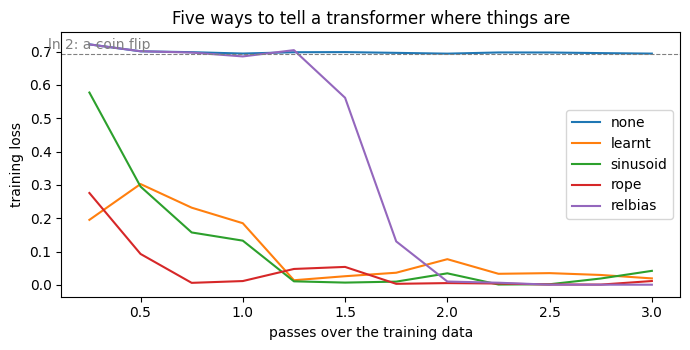

In [12]:
EPOCHS = 3


def train(position, causal=False):
    keras.utils.set_random_seed(SEED)
    model = build_classifier(position, causal)
    losses = []
    for epoch in range(EPOCHS):
        for x, y in train_parts:                               # one length per call: no padding needed
            history = model.fit(x, y, batch_size=64, epochs=1, verbose=0)
            losses.append(history.history["loss"][0])
    return model, losses


def accuracy(model, x, y):
    logits = model.predict(x, batch_size=500, verbose=0)[:, 0]
    return float(np.mean((logits > 0) == (y > 0.5)))


models, curves = {}, {}
print("scheme      params   last loss   accuracy at length 32   seconds")
for position in ("none", "learnt", "sinusoid", "rope", "relbias"):
    t0 = time.time()
    models[position], curves[position] = train(position)
    acc = accuracy(models[position], *tests[32])
    print(f"{position:9s} {models[position].count_params():8,d} {curves[position][-1]:10.3f} {acc:16.3f} {time.time() - t0:16.0f}")
print(f"\nln 2 = {np.log(2):.3f}")

plt.figure(figsize=(7, 3.6))
for position, c in curves.items():
    plt.plot(np.arange(1, len(c) + 1) / len(train_parts), c, label=position)
plt.axhline(np.log(2), color="grey", ls="--", lw=0.8); plt.text(0.05, np.log(2) + 0.015, "ln 2: a coin flip", color="grey")
plt.xlabel("passes over the training data"); plt.ylabel("training loss"); plt.legend(); plt.title("Five ways to tell a transformer where things are")
plt.tight_layout(); plt.show()

### Why we see this

Four models learn the task and get all, or all but a percent or so, of the new rows of length 32 right. The
learnt table is usually the one that drops a few: it has 32 rows to learn from scratch, and the later rows
are seen only by the longer training rows (Step 14 measures this). The model with no positions sits at
0.69, the loss of a coin flip, from the first pass to the last, and scores about 50%.

Look at how it fails. There is no error, no NaN, no warning. The loss is finite and steady. On a real task,
where a bag of words carries part of the answer, a model without positions does not sit at chance: it
trains to a *mediocre* plateau and looks like a model that needs more data or more layers. Next cell: the
proof that no amount of either would help.

In [13]:
x, y = tests[32]
shuffled = np.stack([row[np.random.default_rng(i).permutation(len(row))] for i, row in enumerate(x[:500])])
logits_original = models["none"].predict(x[:500], verbose=0)[:, 0]
logits_shuffled = models["none"].predict(shuffled, verbose=0)[:, 0]
print("model 'none': largest change in the output when each row is shuffled:",
      f"{np.abs(logits_original - logits_shuffled).max():.1e}")
logits_shuffled = models["sinusoid"].predict(shuffled, verbose=0)[:, 0]
print("model 'sinusoid': rows whose answer changes when shuffled:",
      f"{np.mean((models['sinusoid'].predict(x[:500], verbose=0)[:, 0] > 0) != (logits_shuffled > 0)):.1%}")

model 'none': largest change in the output when each row is shuffled: 3.9e-07


model 'sinusoid': rows whose answer changes when shuffled: 50.0%


The trained `none` model gives the same output (to rounding) for every ordering of a row: Step 2's fact,
now for a whole trained network with two blocks. Its two possible labels share the same inputs, so 50% is a
ceiling, not a stage of training. The model with positions changes its answer on about half of the shuffled
rows, as it should: a random shuffle puts A before B half the time.

---
## Step 13 - Sequences longer than any seen in training

All four working models are right on 99% or more of the rows of length 32. Now give them rows of 48, 64, 96
and 128 tokens. The task
has not changed: find A, find B, say which comes first.

> **Predict:** rank the four schemes at length 128, best to worst. Which, if any, will still be near 100%?
> Which will be near 50%?

accuracy     T = 32    T = 48    T = 64    T = 96    T = 128   
none         0.497     0.479     0.484     0.504     0.490     
learnt       0.991     0.702     0.660     0.555     0.508     
sinusoid     0.997     0.755     0.685     0.509     0.422     
rope         1.000     0.888     0.746     0.711     0.677     
relbias      1.000     1.000     1.000     1.000     1.000     
             (trained on lengths 8 to 32 only)


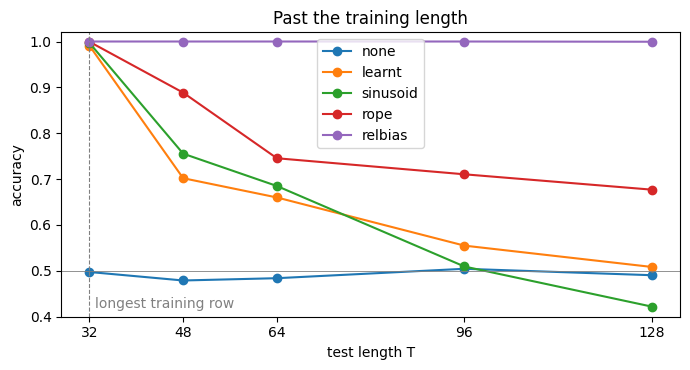

In [14]:
results = {position: [accuracy(m, *tests[L]) for L in TEST_LENGTHS] for position, m in models.items()}
print("accuracy     " + "".join(f"T = {L:<6d}" for L in TEST_LENGTHS))
for position, accs in results.items():
    print(f"{position:9s}    " + "".join(f"{a:<10.3f}" for a in accs))
print("             (trained on lengths 8 to 32 only)")

plt.figure(figsize=(7, 3.8))
for position, accs in results.items():
    plt.plot(TEST_LENGTHS, accs, marker="o", label=position)
plt.axvline(32, color="grey", ls="--", lw=0.8); plt.text(33, 0.42, "longest training row", color="grey")
plt.axhline(0.5, color="grey", lw=0.6)
plt.xticks(TEST_LENGTHS); plt.ylim(0.4, 1.02); plt.xlabel("test length T"); plt.ylabel("accuracy"); plt.legend()
plt.title("Past the training length"); plt.tight_layout(); plt.show()

### Why we see this

- **`learnt`** falls towards chance as soon as the rows get longer, and Step 14 shows exactly why.
- **`sinusoid`** was supposed to extrapolate, and it falls about as fast as the learnt table. The table can
  be *computed* for position 100; the network after it was only ever trained on the fingerprints of
  positions 0 to 31, and it has no reason to treat the new ones sensibly. If it lands *below* 50% at the
  longest length, that is not bad luck: a model applying its rule where the rule no longer holds is not
  guessing, and it can be wrong more often than a coin.
- **`rope`** degrades slowly. Its scores depend only on offsets, so everything it learnt about nearby pairs
  still holds; what is new at length 128 is offsets larger than 31, which it never saw.
- **`relbias`** stays at or near 100%. Its offsets are clipped at ±8, so an offset of +100 lands in the same
  bucket as +8, "far to the right", which it saw thousands of times. For a task that only needs *direction*,
  that is a complete answer.

Be careful what you conclude. The ranking (absolute schemes collapse, relative ones last longer) is what
practitioners find at full size too. The perfect score of the relative bias is a gift of this task: a task
that needed exact distances beyond 8 would defeat the clipping. And the exact numbers move with the seed
(Trial 1). No scheme gives length extrapolation for free.

---
## Step 14 - Why the learnt table fails: rows that were never trained

Two measurements. First, how far each row of the learnt table moved from its starting scale. Second, at
test length 64, the accuracy on rows where both A and B happen to lie inside the first 32 positions, against
rows where at least one lies beyond.

> **Predict:** the accuracy for each of the two groups.

learnt position table: (128, 32)
  mean length of rows  0 to  31 (trained)      : 0.279
  mean length of rows 32 to 127 (never trained): 0.113   (starting scale 0.02 x sqrt(32) = 0.113)



length 32, 'learnt' model (every position was trained, but not equally often):
  A and B both in positions 0 to 23 : 1106 rows, accuracy 0.995
  at least one in positions 24 to 31:  894 rows, accuracy 0.985

length 64, 'learnt' model:
  A and B both in positions 0 to 31 :  516 rows, accuracy 0.994
  at least one beyond position 31   : 1484 rows, accuracy 0.544


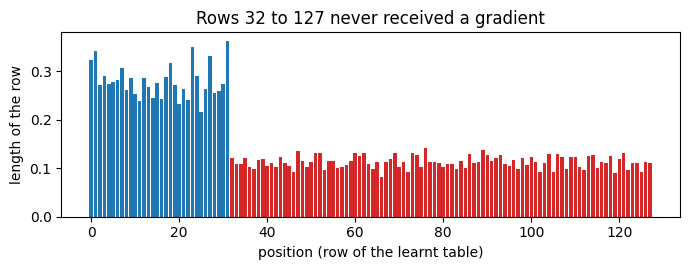

In [15]:
table = models["learnt"].get_layer("position").table.numpy()
norms = np.linalg.norm(table, axis=1)
print("learnt position table:", table.shape)
print(f"  mean length of rows  0 to  31 (trained)      : {norms[:32].mean():.3f}")
print(f"  mean length of rows 32 to 127 (never trained): {norms[32:].mean():.3f}   (starting scale 0.02 x sqrt(32) = {0.02 * np.sqrt(32):.3f})")

x, y = tests[64]
pos_a, pos_b = (x == TOKEN_A).argmax(axis=1), (x == TOKEN_B).argmax(axis=1)
inside = (pos_a < 32) & (pos_b < 32)
correct = (models["learnt"].predict(x, batch_size=500, verbose=0)[:, 0] > 0) == (y > 0.5)
x32, y32 = tests[32]
late = np.maximum((x32 == TOKEN_A).argmax(axis=1), (x32 == TOKEN_B).argmax(axis=1)) >= 24
correct32 = (models["learnt"].predict(x32, batch_size=500, verbose=0)[:, 0] > 0) == (y32 > 0.5)
print(f"\nlength 32, 'learnt' model (every position was trained, but not equally often):")
print(f"  A and B both in positions 0 to 23 : {(~late).sum():4d} rows, accuracy {correct32[~late].mean():.3f}")
print(f"  at least one in positions 24 to 31: {late.sum():4d} rows, accuracy {correct32[late].mean():.3f}")
print(f"\nlength 64, 'learnt' model:")
print(f"  A and B both in positions 0 to 31 : {inside.sum():4d} rows, accuracy {correct[inside].mean():.3f}")
print(f"  at least one beyond position 31   : {(~inside).sum():4d} rows, accuracy {correct[~inside].mean():.3f}")

plt.figure(figsize=(7, 2.8))
plt.bar(np.arange(T_MAX), norms, color=["tab:blue"] * 32 + ["tab:red"] * (T_MAX - 32))
plt.xlabel("position (row of the learnt table)"); plt.ylabel("length of the row")
plt.title("Rows 32 to 127 never received a gradient"); plt.tight_layout(); plt.show()

### Why we see this

The first 32 rows grew to carry a usable signal. The other 96 are still the small random numbers they were
created with: no training row ever reached them, so no gradient ever did. When both markers fall in the
trained region the model is as good as ever; when one falls outside, the model is reading noise where it
expects a position.

The length-32 numbers show the same disease in a milder form, inside the training range. Positions 0 to 7
appear in every training row; positions 24 to 31 appear only in the rows of length 32, a quarter of the
data. More of the learnt model's few errors at length 32 fall there. A real model is the same: short texts
are common and long ones rare, so the last rows of a learnt table are trained on far fewer examples than
the first. And a rule such as "the word two to
my left" has to be learnt separately for every pair of rows, because nothing in a learnt table says that row
41 and row 43 are related the way rows 1 and 3 are.

---
## Step 15 - What the relative bias learnt, and ALiBi's fixed slope

The relative-bias model learnt 17 numbers per head: one for each offset from −8 ("eight or more to the
left") to +8 ("eight or more to the right"). Print them for the first block. Then print the bias that ALiBi
(2021) would add for 6 positions under a causal mask: nothing learnt, a penalty of slope × distance.

> **Predict:** for a task about left and right, what shape should a useful row of 17 numbers have?

offset j - i:     -8    -7    -6    -5    -4    -3    -2    -1     0     1     2     3     4     5     6     7     8
block 0 head 0    0.9   0.3   0.3   0.3   0.3   0.3   0.3   0.3  -0.0  -0.2  -0.3  -0.3  -0.3  -0.3  -0.3  -0.3  -0.9
block 0 head 1   -0.2   0.0  -0.0  -0.0  -0.0  -0.0   0.0   0.0  -0.0   0.0  -0.0   0.0   0.1   0.0   0.0   0.0   0.1

ALiBi bias for 6 positions, slope 0.5, causal (row = the token that is looking, x = masked):
     0.0     x     x     x     x     x
    -0.5   0.0     x     x     x     x
    -1.0  -0.5   0.0     x     x     x
    -1.5  -1.0  -0.5   0.0     x     x
    -2.0  -1.5  -1.0  -0.5   0.0     x
    -2.5  -2.0  -1.5  -1.0  -0.5   0.0


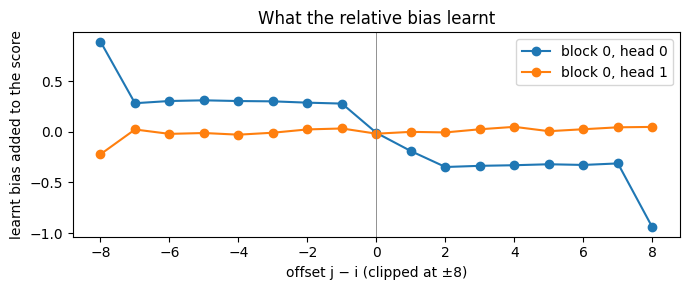

In [16]:
bias = models["relbias"].get_layer("attention_0").bias.numpy()
print("offset j - i:", "".join(f"{o:6d}" for o in range(-CLIP, CLIP + 1)))
for h in range(HEADS):
    print(f"block 0 head {h}", "".join(f"{b:6.1f}" for b in bias[h]))

slope = 0.5
print("\nALiBi bias for 6 positions, slope 0.5, causal (row = the token that is looking, x = masked):")
for row_i in range(6):
    print("  " + "".join(f"{0.0 - slope * (row_i - col_j):6.1f}" if col_j <= row_i else "     x" for col_j in range(6)))

plt.figure(figsize=(7, 3))
for h in range(HEADS):
    plt.plot(np.arange(-CLIP, CLIP + 1), bias[h], marker="o", label=f"block 0, head {h}")
plt.axvline(0, color="grey", lw=0.6); plt.xlabel("offset j − i (clipped at ±8)"); plt.ylabel("learnt bias added to the score")
plt.legend(); plt.title("What the relative bias learnt"); plt.tight_layout(); plt.show()

### Why we see this

Look for a row that is lopsided: one sign for negative offsets (tokens to the left), the other for positive
offsets (tokens to the right). That is a head that leans to one side. (A head whose row stayed near zero
was not needed for position; the model found another use for it.) Give the token `A` such a head and it
picks up more of `B` when `B` is on that side than when it is on the other, and the rest of the network
turns "more" and "less" into the answer. The same few numbers apply at every position and every length.

ALiBi fixes the shape in advance instead of learning it: the further away a token, the larger the penalty,
with a different slope for each head. Under a causal mask every other token is to the left, so distance is
all there is to say. Without a causal mask a penalty on |i − j| is the same to the left and to the right,
and it cannot tell A-then-B from B-then-A at all (Trial 5).

---
## Step 16 - The causal mask is a position signal

Step 3 showed that masked attention is not blind to order. How much can a model do with that alone? Train
the `none` model once more with `causal=True`: no table, no rotation, no bias. Each token may attend only
to itself and to tokens on its left.

> **Predict:** chance, like the unmasked `none` model? Or better? Think about what the token `B` can see
> when `A` is to its left, and when it is not.

In [17]:
t0 = time.time()
causal_model, causal_curve = train("none", causal=True)
causal_accs = [accuracy(causal_model, *tests[L]) for L in TEST_LENGTHS]
print(f"'none' + causal mask: {causal_model.count_params():,} parameters, last loss {causal_curve[-1]:.3f}, {time.time() - t0:.0f} s")
print("accuracy     " + "".join(f"T = {L:<6d}" for L in TEST_LENGTHS))
print("none         " + "".join(f"{a:<10.3f}" for a in results["none"]))
print("none+causal  " + "".join(f"{a:<10.3f}" for a in causal_accs))

'none' + causal mask: 17,505 parameters, last loss 0.000, 17 s
accuracy     T = 32    T = 48    T = 64    T = 96    T = 128   
none         0.497     0.479     0.484     0.504     0.490     
none+causal  1.000     1.000     1.000     1.000     1.000     


### Why we see this

With the mask, `B` can see `A` only if `A` is on its left. "Did I find an A?" is then the answer to the
task, and the model learns it perfectly, at every length, with no position encoding of any kind.

This is why a GPT-style decoder trained with **no** positions still learns a usable language model, and why
"it trains without positions" does not prove that positions were wired in correctly. The mask gives a
direction (before or after), not a distance: it cannot tell "the previous word" from "a word forty back"
without extra work. Real decoders still get an explicit scheme.

---
## Step 17 - The whole lab in one table

In [18]:
print("where position enters        scheme       extra params   T = 32   T = 64   T = 128")
rows = [("nowhere", "none"), ("input vector, trainable", "learnt"), ("input vector, fixed", "sinusoid"),
        ("queries and keys", "rope"), ("attention scores", "relbias")]
for place, position in rows:
    extra = count_classifier(position)[1]
    r = dict(zip(TEST_LENGTHS, results[position]))
    print(f"{place:28s} {position:10s} {extra:12,d} {r[32]:9.3f} {r[64]:8.3f} {r[128]:8.3f}")
r = dict(zip(TEST_LENGTHS, causal_accs))
print(f"{'nowhere, but causal mask':28s} {'none':10s} {0:12,d} {r[32]:9.3f} {r[64]:8.3f} {r[128]:8.3f}")
print(f"\nwhole notebook: {time.time() - t_start:.0f} seconds")

where position enters        scheme       extra params   T = 32   T = 64   T = 128
nowhere                      none                  0     0.497    0.484    0.490
input vector, trainable      learnt            4,096     0.991    0.660    0.508
input vector, fixed          sinusoid              0     0.997    0.685    0.422
queries and keys             rope                  0     1.000    0.746    0.677
attention scores             relbias              68     1.000    1.000    1.000
nowhere, but causal mask     none                  0     1.000    1.000    1.000

whole notebook: 114 seconds


---
## Trials: change one thing at a time

| # | Change | Predict | Observe |
|---|---|---|---|
| 1 | Step 1: `SEED = 7` and run everything again | Which numbers in Step 13 move, and does the *ranking* change? | |
| 2 | Step 8: `TRAIN_LENGTHS = (32,)` and `N_TRAIN_EACH = 12000` | Does training at one length help or hurt each scheme at T = 64? | |
| 3 | Step 9: `CLIP = 2` | Extra parameters for `relbias`? Does it still solve the task and still extrapolate? | |
| 4 | Step 9: in `build_classifier`, `GlobalAveragePooling1D` in place of `GlobalMaxPooling1D` | Does `none` still score 50%? Which scheme suffers most at T = 128? | |
| 5 | Step 12: add `"alibi"` to the list of schemes | A symmetric distance penalty, no causal mask: loss and accuracy? | |
| 6 | Step 16: `train("alibi", causal=True)` | Compare with Trial 5. What did the mask add? | |
| 7 | Step 12: `EPOCHS = 9`, scheme `none` only | Will three times the training move the loss off 0.693? | |
| 8 | Step 4: `base=100.0` in `sinusoid_table` (and in Step 5) | Slowest wavelength? What happens to the similarity curve at large offsets? | |

---
## Exercises

1. **Sorted or not.** Change `make_data` so that a row is either sorted in increasing order or is the same
   sorted row with two neighbours swapped. Which schemes solve it? Which extrapolate? Why is this task harder
   for the clipped relative bias than "A before B" was?
2. **How far apart?** Change the label to "A and B are fewer than 12 positions apart". Predict which scheme
   now extrapolates best, and why `CLIP = 8` is no longer enough. Run it with `CLIP = 16`.
3. **Rotate the values too.** In `SelfAttention.call`, rotate `v` as well when `kind == "rope"`. Train, and
   test at length 64. Then explain in two sentences what the pooled output now contains that it should not.
4. **Left padding.** Take a length-16 test row and pad it on the left with 16 filler tokens, so that its real
   content starts at position 16. Compare the `learnt` and `relbias` models on padded and unpadded rows. What
   would you have to pass to the `learnt` model to make padding harmless?
5. **The similarity that matters.** Step 5 used raw dot products. Train the `sinusoid` model, then compute
   the *attention scores* of block 0 between two filler tokens as a function of their offset. Do the scores
   still depend only on the offset?
6. **Position by counting.** With `causal=True` and no positions, design by hand (on paper) a head that lets
   each token estimate how far it is from the start. Hint: attend uniformly, and put one special token first.

---
## Cheat sheet

| Fact | Value / rule |
|---|---|
| Self-attention with no positions | permutation-equivariant: shuffle in, same shuffle out |
| With pooling on top | permutation-invariant: every ordering gets the same answer |
| RNNs and CNNs | order is built into the computation; they never needed positions |
| Sinusoidal table (2017) | pair i holds sin and cos of `pos / 10000^(2i/d)`; added to the input; 0 parameters |
| Its wavelengths | from 6.28 positions to about 10,000 × 6.28; similarity of two rows depends only on the offset |
| Learnt table (BERT, GPT-2) | T × d parameters, added to the input; hard cap at T; rows past the training length are untrained |
| GPT-2 small's table | 1,024 × 768 = 786,432 |
| RoPE (2021) | rotate each pair of query and key coordinates by position × speed; score depends on the offset; 0 parameters; never the values |
| Relative bias (T5) | a learnt number per offset bucket and head, added to the scores |
| ALiBi (2021) | subtract slope × distance from the scores; fixed slopes; meant for causal models |
| Three places | input vector (add), queries and keys (rotate), scores (bias) |
| No positions at all | no error; the loss sits at a plateau (ln 2 = 0.693 on this task) |
| Lab, T = 32 | every scheme with positions: about 100%; none: about 50% |
| Lab, T = 128 | learnt and sinusoid near chance; RoPE in between; clipped relative bias near 100% (on this task) |
| Causal mask | leaks order: `none` + mask solves "A before B" at every length |
| Rule | test at the length you will serve; never assume a model trained at 512 works at 4,096 |